In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.metrics import confusion_matrix
import seaborn as sns


In [3]:
(X_train_image, y_train_label), (X_test_image, y_test_label) = fashion_mnist.load_data()
print(X_train_image.shape)
print(y_train_label.shape)
print(X_test_image.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28)
(60000,)
(10000, 28, 28)


/tmp/ipykernel_3070/516601541.py:12: UserWarning: Glyph 30701 (\N{CJK UNIFIED IDEOGRAPH-77ED}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3070/516601541.py:12: UserWarning: Glyph 38772 (\N{CJK UNIFIED IDEOGRAPH-9774}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3070/516601541.py:12: UserWarning: Glyph 24676 (\N{CJK UNIFIED IDEOGRAPH-6064}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3070/516601541.py:12: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3070/516601541.py:12: UserWarning: Glyph 34915 (\N{CJK UNIFIED IDEOGRAPH-8863}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 30701 (\N{CJK UNIFIED IDEOGRAPH-77ED}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPyt

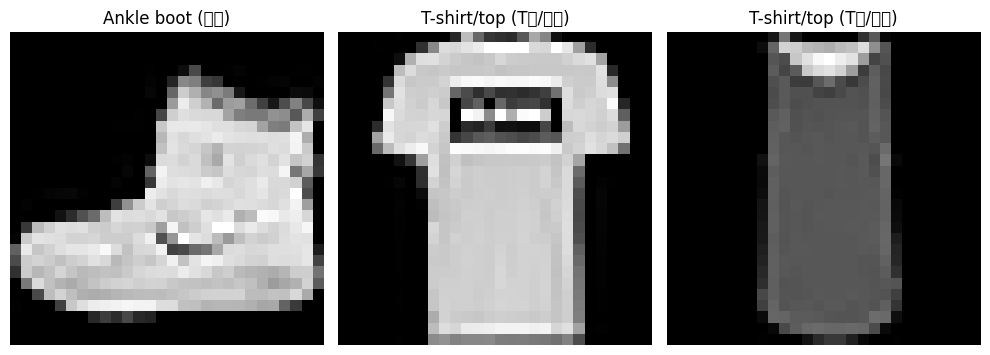

In [4]:
class_names = {
    0: "T-shirt/top (T恤/上衣)", 1: "Trouser (褲子)", 2: "Pullover (套頭毛衣)",
    3: "Dress (洋裝)", 4: "Coat (外套)", 5: "Sandal (涼鞋)",
    6: "Shirt (襯衫)", 7: "Sneaker (運動鞋)", 8: "Bag (包包)", 9: "Ankle boot (短靴)"
}
plt.figure(figsize=(10, 4))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(X_train_image[i], cmap="gray")
    plt.title(class_names[y_train_label[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()


In [5]:
x_Train = X_train_image.reshape(60000, 784).astype('float32') / 255.0
x_Test = X_test_image.reshape(10000, 784).astype('float32') / 255.0
y_TrainOneHot = to_categorical(y_train_label)
y_TestOneHot = to_categorical(y_test_label)


In [6]:
model = Sequential()
model.add(Dense(units=512, input_dim=784, kernel_initializer='normal', activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(units=256, kernel_initializer='normal', activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(units=10, kernel_initializer='normal', activation='softmax'))
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
train_history = model.fit(x=x_Train, y=y_TrainOneHot, validation_split=0.2, epochs=25, batch_size=256, verbose=1)


Epoch 1/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.7864 - loss: 0.6069 - val_accuracy: 0.8466 - val_loss: 0.4258
Epoch 2/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.8530 - loss: 0.4073 - val_accuracy: 0.8568 - val_loss: 0.3890
Epoch 3/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.8673 - loss: 0.3643 - val_accuracy: 0.8746 - val_loss: 0.3472
Epoch 4/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.8764 - loss: 0.3370 - val_accuracy: 0.8754 - val_loss: 0.3399
Epoch 5/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.8824 - loss: 0.3179 - val_accuracy: 0.8698 - val_loss: 0.3517
Epoch 6/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.8864 - loss: 0.3046 - val_accuracy: 0.8857 - val_loss: 0.3204
Epoch 7/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.8901 - loss: 0.2941 - val_accuracy: 0.8802 - val_loss: 0.3286
Epoch 8/25
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.8946 - loss: 0.2813 - val_accu

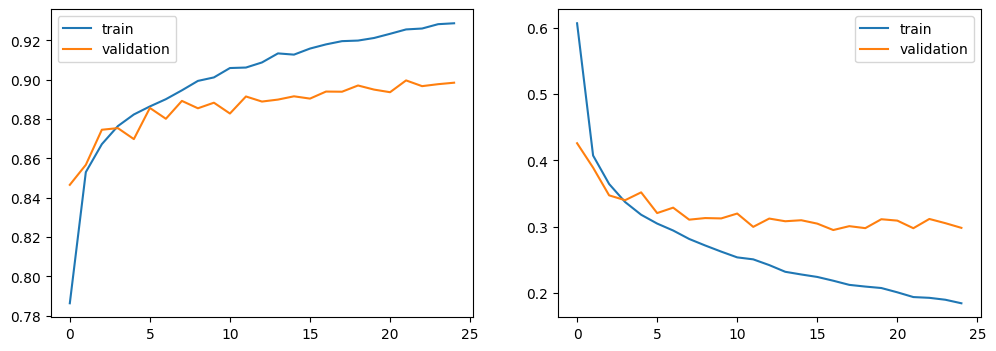

In [8]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_history.history['accuracy'])
plt.plot(train_history.history['val_accuracy'])
plt.legend(['train', 'validation'])
plt.subplot(1, 2, 2)
plt.plot(train_history.history['loss'])
plt.plot(train_history.history['val_loss'])
plt.legend(['train', 'validation'])
plt.show()


In [9]:
scores = model.evaluate(x_Test, y_TestOneHot, verbose=0)
print(scores[1])


0.8967000246047974


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


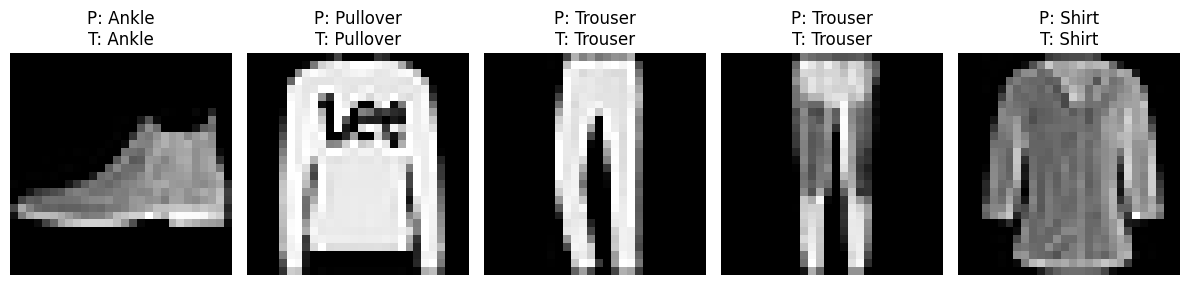

In [10]:
predictions = model.predict(x_Test)
prediction_labels = np.argmax(predictions, axis=1)
plt.figure(figsize=(12, 5))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test_image[i], cmap='gray')
    plt.title(f"P: {class_names[prediction_labels[i]].split(' ')[0]}\nT: {class_names[y_test_label[i]].split(' ')[0]}")
    plt.axis('off')
plt.tight_layout()
plt.show()


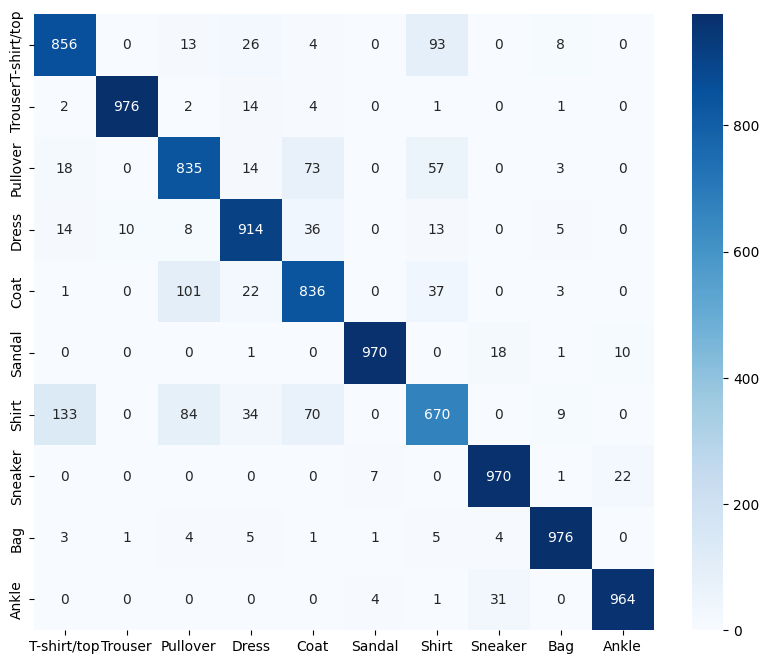

In [11]:
cm = confusion_matrix(y_test_label, prediction_labels)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[class_names[k].split(' ')[0] for k in range(10)], yticklabels=[class_names[k].split(' ')[0] for k in range(10)])
plt.show()


In [12]:
model.save('fashion_mnist_dnn_model.h5')
